# Lab 6 — “Field Trial”: Voice Emergency Stop with Live Audio

**Aim:** Load the INT8 keyword-spotting model from Lab 5 and test it with dataset clips, phone recordings, live microphone audio and continuous streaming inference.

**Classes:** `stop`, `_unknown_`, `_silence_`  
**Required input:** `kws_int8.tflite` and `kws_config.json` exported by Lab 5.

### What this notebook implements
1. Load the INT8 model and the exact MFCC/normalisation settings from Lab 5.
2. Print input/output tensor shapes, data types and quantisation parameters.
3. Test 15 Speech Commands clips: 5 STOP, 5 other words and 5 silence/noise clips.
4. Test 10 phone-recorded clips: 5 STOP and 5 other words.
5. Record 20 live microphone trials: 10 STOP and 10 other words.
6. Run 15–20 second streaming inference using a 1-second window updated every 100 ms, 3-prediction smoothing, threshold 0.7 and a 1-second refractory period.
7. Compare thresholds 0.5, 0.7 and 0.9 using the same streaming recording.
8. Plot waveform and STOP score over time, marking every `🛑 BELT STOPPED` event.
9. Measure model size, MFCC processing time and TFLite inference time; repeat streaming at 1 metre with background noise.

> **Important:** This is a classroom prototype. The screen message simulates a stop command; it does not control or certify a conveyor emergency-stop circuit. A real machine must retain an independent, fail-safe physical emergency stop.

## How to run this notebook

- Open this notebook in **Google Colab** and run cells from top to bottom.
- In the first upload cell, upload `kws_int8.tflite` and `kws_config.json` from Lab 5. `kws_mfcc_dataset.csv` from the Lab 5 output bundle is strongly recommended: it lets this notebook exclude speakers used in Lab 5 training/validation. Also upload `factory_noise.wav` if you have a real ambient recording.
- For phone recordings, make a ZIP containing 10 audio files. Name them `stop_01.wav` ... `stop_05.wav` and `other_01.wav` ... `other_05.wav`. MP3/M4A/WebM are also accepted if FFmpeg can decode them.
- The live microphone cells use your browser's microphone permission. Use Chrome/Edge in Colab and allow microphone access.
- For streaming and threshold evaluation, write down the approximate times (in seconds from the start of the recording) when you said STOP. Example: `3.2, 8.4, 14.7`.
- The notebook saves result tables, plots, performance information and a ZIP bundle in `/content/lab6_outputs`.

**Interpretation rule:** Outputs are calculated from your recordings and model. Do not copy the expected-results figures from the assignment as if they were measured results.

## 1. Install and import the required libraries

In [5]:
!apt-get -qq update
!apt-get -qq install -y ffmpeg
!pip -q install soundfile

import os, json, time, math, base64, zipfile, shutil, random, subprocess, urllib.request
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import tensorflow as tf
from scipy.signal import resample_poly
from sklearn.metrics import confusion_matrix, accuracy_score
from IPython.display import display, Javascript, Audio
from google.colab import files, output

SEED = 42
rng = np.random.default_rng(SEED)
random.seed(SEED)
np.set_printoptions(precision=4, suppress=True)

OUT_DIR = Path('/content/lab6_outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__)
print('FFmpeg:', subprocess.run(['ffmpeg', '-version'], capture_output=True, text=True).stdout.splitlines()[0])
print('Google Colab microphone capture will be used in the live-test sections.')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
TensorFlow: 2.21.0
FFmpeg: ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
Google Colab microphone capture will be used in the live-test sections.


## 2. Upload the Lab 5 model and configuration

In [6]:
print('Upload these two required Lab 5 files: kws_int8.tflite and kws_config.json.')
print('Optional: kws_mfcc_dataset.csv and factory_noise.wav.')
uploaded = files.upload()

# Copy uploaded files into a stable working folder.
UPLOAD_DIR = Path('/content/lab6_uploads')
UPLOAD_DIR.mkdir(exist_ok=True)
for name, data in uploaded.items():
    (UPLOAD_DIR / Path(name).name).write_bytes(data)

model_candidates = list(UPLOAD_DIR.glob('*.tflite'))
config_candidates = list(UPLOAD_DIR.glob('kws_config.json'))
if not model_candidates:
    raise FileNotFoundError('Upload the Lab 5 INT8 .tflite model (normally kws_int8.tflite).')
if not config_candidates:
    raise FileNotFoundError('Upload kws_config.json exported by Lab 5.')

MODEL_PATH = model_candidates[0]
CONFIG_PATH = config_candidates[0]
config = json.loads(CONFIG_PATH.read_text())

LABELS = config.get('classes_in_output_order', ['stop', '_unknown_', '_silence_'])
if LABELS != ['stop', '_unknown_', '_silence_']:
    raise ValueError(f'Unexpected class order in config: {LABELS}')
SAMPLE_RATE = int(config.get('sample_rate_hz', 16000))
CLIP_SAMPLES = int(config.get('clip_samples', SAMPLE_RATE))
FRAME_LENGTH = int(config.get('frame_length_samples', 480))
FRAME_STEP = int(config.get('frame_step_samples', 320))
FFT_LENGTH = int(config.get('fft_length', 512))
NUM_MEL_BINS = int(config.get('mel_bins', 40))
NUM_MFCC = int(config.get('mfcc_coefficients', 10))
EXPECTED_FRAMES = int(config.get('mfcc_shape_frames_coefficients', [49, 10])[0])
EXPECTED_COEFFICIENTS = int(config.get('mfcc_shape_frames_coefficients', [49, 10])[1])

norm = config.get('normalization', {})
if 'mean_by_mfcc_coefficient' not in norm or 'std_by_mfcc_coefficient' not in norm:
    raise KeyError('kws_config.json must contain normalization.mean_by_mfcc_coefficient and std_by_mfcc_coefficient.')
MFCC_MEAN = np.asarray(norm['mean_by_mfcc_coefficient'], dtype=np.float32).reshape(1, 1, -1)
MFCC_STD = np.asarray(norm['std_by_mfcc_coefficient'], dtype=np.float32).reshape(1, 1, -1)
if MFCC_MEAN.shape[-1] != NUM_MFCC or MFCC_STD.shape[-1] != NUM_MFCC:
    raise ValueError('MFCC normalisation arrays do not match the configured number of coefficients.')
if np.any(MFCC_STD <= 0):
    raise ValueError('One or more MFCC standard deviations are not positive.')

print('Model:', MODEL_PATH.name, f'({MODEL_PATH.stat().st_size / 1024:.2f} KB)')
print('Config:', CONFIG_PATH.name)
print('MFCC settings:', SAMPLE_RATE, 'Hz |', FRAME_LENGTH, 'sample frame |', FRAME_STEP, 'sample hop |', EXPECTED_FRAMES, 'x', NUM_MFCC)
print('Class order:', LABELS)

# Retain optional Lab 5 metadata and real ambient noise if they were uploaded.
LAB5_CSV = next(iter(UPLOAD_DIR.glob('kws_mfcc_dataset.csv')), None)
FACTORY_NOISE_PATH = next(iter(UPLOAD_DIR.glob('factory_noise.wav')), None)
print('Lab 5 MFCC metadata supplied:', LAB5_CSV is not None)
print('Real factory-noise file supplied:', FACTORY_NOISE_PATH is not None)

Upload these two required Lab 5 files: kws_int8.tflite and kws_config.json.
Optional: kws_mfcc_dataset.csv and factory_noise.wav.


Saving kws_config.json to kws_config.json
Saving kws_int8.tflite to kws_int8 (1).tflite
Model: kws_int8.tflite (70.51 KB)
Config: kws_config.json
MFCC settings: 16000 Hz | 480 sample frame | 320 sample hop | 49 x 10
Class order: ['stop', '_unknown_', '_silence_']
Lab 5 MFCC metadata supplied: False
Real factory-noise file supplied: False


## 3. Load the INT8 TFLite model and inspect its tensors

In [7]:
interpreter = tf.lite.Interpreter(model_path=str(MODEL_PATH), num_threads=1)
interpreter.allocate_tensors()
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]

input_shape = tuple(int(x) for x in input_detail['shape'])
output_shape = tuple(int(x) for x in output_detail['shape'])
in_scale, in_zero = input_detail['quantization']
out_scale, out_zero = output_detail['quantization']

print('Input shape:', input_shape)
print('Input dtype:', input_detail['dtype'])
print('Input quantisation scale / zero point:', in_scale, in_zero)
print('Output shape:', output_shape)
print('Output dtype:', output_detail['dtype'])
print('Output quantisation scale / zero point:', out_scale, out_zero)
print('Expected input:', '(1, 49, 10, 1) int8; expected output: (1, 3) int8')

if input_detail['dtype'] != np.int8 or output_detail['dtype'] != np.int8:
    raise TypeError('The uploaded model is not full INT8 at both input and output. Re-export full INT8 from Lab 5.')
if input_shape not in [(1, EXPECTED_FRAMES, NUM_MFCC, 1), (1, 1, EXPECTED_FRAMES, NUM_MFCC, 1)]:
    raise ValueError(f'Model input shape {input_shape} does not match the Lab 5 MFCC configuration.')
if output_shape[-1] != 3:
    raise ValueError(f'Expected 3 output classes, got {output_shape}.')
if in_scale <= 0 or out_scale <= 0:
    raise ValueError('Invalid INT8 quantisation scale in the TFLite model.')

print('\nModel loading check passed. The model expects normalised MFCC features, not raw audio.')

Input shape: (1, 49, 10, 1)
Input dtype: <class 'numpy.int8'>
Input quantisation scale / zero point: 0.05407136678695679 -1
Output shape: (1, 3)
Output dtype: <class 'numpy.int8'>
Output quantisation scale / zero point: 0.00390625 -128
Expected input: (1, 49, 10, 1) int8; expected output: (1, 3) int8

Model loading check passed. The model expects normalised MFCC features, not raw audio.


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


### What this tells us

The microphone does not send sound directly into the neural network. First, the audio must be converted to the same 49 × 10 MFCC representation and standardised using the Lab 5 training mean and standard deviation. The INT8 scale and zero point then convert those values into the integer format expected by the model.

## 4. Recreate the exact Lab 5 audio and MFCC preprocessing

In [8]:
# These values match the Lab 5 notebook's MFCC implementation.
MEL_MATRIX = tf.signal.linear_to_mel_weight_matrix(
    num_mel_bins=NUM_MEL_BINS,
    num_spectrogram_bins=FFT_LENGTH // 2 + 1,
    sample_rate=SAMPLE_RATE,
    lower_edge_hertz=20.0,
    upper_edge_hertz=7600.0,
)

def audio_to_mfcc(wave):
    """Convert one 16 kHz mono one-second waveform to the Lab 5 (49, 10) MFCCs."""
    wave = np.asarray(wave, dtype=np.float32).reshape(-1)
    if len(wave) != CLIP_SAMPLES:
        raise ValueError(f'Expected {CLIP_SAMPLES} samples, received {len(wave)}.')
    stft = tf.signal.stft(
        tf.convert_to_tensor(wave, dtype=tf.float32),
        frame_length=FRAME_LENGTH,
        frame_step=FRAME_STEP,
        fft_length=FFT_LENGTH,
        window_fn=tf.signal.hann_window,
        pad_end=False,
    )
    power = tf.square(tf.abs(stft))
    mel_power = tf.matmul(power, MEL_MATRIX)
    log_mel = tf.math.log(mel_power + 1e-6)
    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :NUM_MFCC]
    mfcc = mfcc.numpy().astype(np.float32)
    if mfcc.shape != (EXPECTED_FRAMES, NUM_MFCC):
        raise ValueError(f'MFCC shape mismatch: {mfcc.shape}')
    return mfcc

def normalise_mfcc(mfcc):
    return ((mfcc[np.newaxis, ...] - MFCC_MEAN) / MFCC_STD)[..., np.newaxis].astype(np.float32)

def quantise_input(x_float):
    q = np.round(x_float / in_scale + in_zero)
    return np.clip(q, -128, 127).astype(np.int8)

def invoke_int8(x_float, timing=True):
    """Run one normalised float MFCC tensor through the INT8 interpreter."""
    x_float = np.asarray(x_float, dtype=np.float32)
    if x_float.shape == (EXPECTED_FRAMES, NUM_MFCC, 1):
        x_float = x_float[np.newaxis, ...]
    q = quantise_input(x_float)
    start = time.perf_counter()
    interpreter.set_tensor(input_detail['index'], q)
    interpreter.invoke()
    elapsed_ms = (time.perf_counter() - start) * 1000.0
    raw = interpreter.get_tensor(output_detail['index']).astype(np.float32)
    probs = (raw - out_zero) * out_scale
    probs = np.maximum(probs.squeeze(), 0.0)
    # Softmax output should already sum close to one; normalise tiny quantisation drift.
    if probs.sum() > 0:
        probs = probs / probs.sum()
    return probs.astype(np.float32), elapsed_ms

def predict_wave(wave):
    mfcc = audio_to_mfcc(wave)
    x = normalise_mfcc(mfcc)
    probs, invoke_ms = invoke_int8(x)
    return probs, mfcc, invoke_ms

def read_wav(path):
    data, sr = sf.read(str(path), dtype='float32', always_2d=True)
    mono = data.mean(axis=1)
    if sr != SAMPLE_RATE:
        from math import gcd
        g = gcd(int(sr), SAMPLE_RATE)
        mono = resample_poly(mono, SAMPLE_RATE // g, int(sr) // g).astype(np.float32)
    return np.asarray(mono, dtype=np.float32)

def one_second_clip(wave):
    """Use the highest-energy one-second segment, or zero-pad a short clip."""
    wave = np.asarray(wave, dtype=np.float32).reshape(-1)
    if len(wave) < CLIP_SAMPLES:
        return np.pad(wave, (0, CLIP_SAMPLES - len(wave))).astype(np.float32)
    if len(wave) == CLIP_SAMPLES:
        return wave.copy()
    hop = max(1, SAMPLE_RATE // 10)
    starts = range(0, len(wave) - CLIP_SAMPLES + 1, hop)
    best_start, best_energy = 0, -1.0
    for start in starts:
        segment = wave[start:start + CLIP_SAMPLES]
        energy = float(np.mean(segment ** 2))
        if energy > best_energy:
            best_start, best_energy = start, energy
    return wave[best_start:best_start + CLIP_SAMPLES].copy()

def convert_to_16k_wav(source, destination):
    cmd = ['ffmpeg', '-hide_banner', '-loglevel', 'error', '-y', '-i', str(source), '-ac', '1', '-ar', str(SAMPLE_RATE), '-c:a', 'pcm_s16le', str(destination)]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f'Could not decode {source}: {result.stderr[-1200:]}')
    return Path(destination)

# Quick consistency check using a one-second dummy waveform.
_demo = np.zeros(CLIP_SAMPLES, dtype=np.float32)
_demo_mfcc = audio_to_mfcc(_demo)
_demo_x = normalise_mfcc(_demo_mfcc)
_demo_probs, _demo_ms = invoke_int8(_demo_x)
print('MFCC shape:', _demo_mfcc.shape)
print('Normalised model input shape:', _demo_x.shape)
print('Dummy output probabilities:', dict(zip(LABELS, _demo_probs.round(4))))
print('Output probability sum:', round(float(_demo_probs.sum()), 4))

MFCC shape: (49, 10)
Normalised model input shape: (1, 49, 10, 1)
Dummy output probabilities: {'stop': np.float32(0.0938), '_unknown_': np.float32(0.3398), '_silence_': np.float32(0.5664)}
Output probability sum: 1.0


## 5. Common prediction helper and STOP decision

The TFLite model returns three class scores. For the field trial, we treat STOP as detected only when its probability reaches the selected threshold. If it does not, the system reports the stronger of `_unknown_` and `_silence_`.

This separates the **model's highest-probability class** from the **STOP alarm decision**. A lower STOP threshold is more sensitive but may produce more false stops.

In [9]:
DEFAULT_THRESHOLD = 0.7

def decision_from_probs(probs, threshold=DEFAULT_THRESHOLD):
    stop_score = float(probs[0])
    if stop_score >= threshold:
        return 'stop'
    non_stop_idx = 1 + int(np.argmax(probs[1:]))
    return LABELS[non_stop_idx]

def describe_prediction(probs, threshold=DEFAULT_THRESHOLD):
    top_idx = int(np.argmax(probs))
    return {
        'predicted_class_argmax': LABELS[top_idx],
        'confidence': float(probs[top_idx]),
        'stop_score': float(probs[0]),
        'system_decision': decision_from_probs(probs, threshold),
    }

print('Default STOP threshold:', DEFAULT_THRESHOLD)
print('At threshold 0.7, the system only shows BELT STOPPED if the STOP score is at least 0.7.')

Default STOP threshold: 0.7
At threshold 0.7, the system only shows BELT STOPPED if the STOP score is at least 0.7.


## 6. Bench test: 15 unseen Speech Commands clips

We choose five `stop` clips and five clips from other words, then create five silence/noise clips. If `kws_mfcc_dataset.csv` from Lab 5 is uploaded, its speaker IDs are used to avoid speakers assigned to Lab 5 training/validation. If that CSV is not supplied, the notebook can still test 15 clips, but it cannot prove that their speakers were excluded from Lab 5 training/validation.

In [10]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
DATA_ZIP = Path('/content/mini_speech_commands.zip')
DATA_ROOT = Path('/content/mini_speech_commands')
if not DATA_ROOT.exists():
    if not DATA_ZIP.exists():
        print('Downloading Mini Speech Commands...')
        urllib.request.urlretrieve(DATA_URL, DATA_ZIP)
    with zipfile.ZipFile(DATA_ZIP) as zf:
        zf.extractall('/content')

# Locate the extracted word folders.
if not DATA_ROOT.exists():
    candidates = [p for p in Path('/content').glob('**/stop') if p.is_dir()]
    if not candidates:
        raise FileNotFoundError('Could not locate the extracted Mini Speech Commands stop folder.')
    DATA_ROOT = candidates[0].parent

word_dirs = {p.name: p for p in DATA_ROOT.iterdir() if p.is_dir()}
required_words = {'stop', 'go', 'down', 'left', 'no', 'right', 'up', 'yes'}
missing = required_words - set(word_dirs)
if missing:
    raise ValueError(f'Dataset is missing expected folders: {sorted(missing)}')

train_val_speakers = set()
if LAB5_CSV is not None:
    lab5_meta = pd.read_csv(LAB5_CSV, usecols=['split', 'speaker_id'])
    train_val_speakers = set(lab5_meta.loc[lab5_meta['split'].isin(['train', 'validation']), 'speaker_id'].astype(str))
    print('Excluding', len(train_val_speakers), 'Lab 5 training/validation speaker IDs.')
else:
    print('WARNING: No Lab 5 MFCC CSV uploaded. Speaker separation from Lab 5 cannot be verified.')

def speaker_from_filename(path):
    stem = Path(path).stem
    return stem.split('_nohash_')[0] if '_nohash_' in stem else stem

all_stop = sorted(word_dirs['stop'].glob('*.wav'))
all_other = []
for word in sorted(required_words - {'stop'}):
    all_other.extend(sorted(word_dirs[word].glob('*.wav')))

if train_val_speakers:
    all_stop = [p for p in all_stop if speaker_from_filename(p) not in train_val_speakers]
    all_other = [p for p in all_other if speaker_from_filename(p) not in train_val_speakers]

rng.shuffle(all_stop)
rng.shuffle(all_other)
selected_stop, selected_other = [], []
used_speakers = set()
for p in all_stop:
    sp = speaker_from_filename(p)
    if sp not in used_speakers:
        selected_stop.append(p); used_speakers.add(sp)
    if len(selected_stop) == 5: break
for p in all_other:
    sp = speaker_from_filename(p)
    if sp not in used_speakers:
        selected_other.append(p); used_speakers.add(sp)
    if len(selected_other) == 5: break
if len(selected_stop) < 5 or len(selected_other) < 5:
    raise RuntimeError('Not enough eligible audio clips. Check the dataset and Lab 5 speaker metadata.')

# Create silence windows from real uploaded factory noise when available; otherwise use a documented synthetic fallback.
if FACTORY_NOISE_PATH is not None:
    ambient = read_wav(FACTORY_NOISE_PATH)
else:
    ambient = None

def make_silence_clip(index):
    if ambient is not None and len(ambient) >= CLIP_SAMPLES:
        max_start = len(ambient) - CLIP_SAMPLES
        start = int(rng.integers(0, max_start + 1))
        noise = ambient[start:start + CLIP_SAMPLES].copy()
        noise = noise - noise.mean()
        rms = np.sqrt(np.mean(noise ** 2)) + 1e-8
        noise *= 0.01 / rms
        source = 'uploaded factory_noise.wav'
    else:
        white = rng.normal(size=CLIP_SAMPLES)
        slow = np.interp(np.linspace(0, 255, CLIP_SAMPLES), np.arange(256), rng.normal(size=256))
        noise = 0.7 * white + 0.3 * slow
        noise -= noise.mean()
        noise *= 0.01 / (np.sqrt(np.mean(noise ** 2)) + 1e-8)
        source = 'synthetic coloured noise fallback'
    return np.clip(noise, -1, 1).astype(np.float32), source

bench_records = []
for p in selected_stop:
    bench_records.append({'path': p, 'actual': 'stop', 'source': 'Speech Commands'})
for p in selected_other:
    bench_records.append({'path': p, 'actual': '_unknown_', 'source': 'Speech Commands'})

bench_rows = []
for i, item in enumerate(bench_records):
    wave = one_second_clip(read_wav(item['path']))
    probs, mfcc, invoke_ms = predict_wave(wave)
    info = describe_prediction(probs)
    bench_rows.append({
        'file': item['path'].name,
        'actual_class': item['actual'],
        **info,
        'stop_probability': float(probs[0]),
        'argmax_correct': info['predicted_class_argmax'] == item['actual'],
        'stop_decision_correct': decision_from_probs(probs) == 'stop' if item['actual'] == 'stop' else decision_from_probs(probs) != 'stop',
        'invoke_time_ms': invoke_ms,
        'source': item['source'],
    })

silence_rows = []
for i in range(5):
    wave, noise_source = make_silence_clip(i)
    probs, mfcc, invoke_ms = predict_wave(wave)
    info = describe_prediction(probs)
    silence_rows.append({
        'file': f'silence_noise_{i+1:02d}', 'actual_class': '_silence_', **info,
        'stop_probability': float(probs[0]), 'argmax_correct': info['predicted_class_argmax'] == '_silence_',
        'stop_decision_correct': decision_from_probs(probs) != 'stop',
        'invoke_time_ms': invoke_ms, 'source': noise_source,
    })

bench_df = pd.DataFrame(bench_rows + silence_rows)
display(bench_df.round(4))
bench_df.to_csv(OUT_DIR / 'bench_15_clips.csv', index=False)
print('Bench clips:', len(bench_df))
print('Three-class argmax accuracy:', f"{bench_df['argmax_correct'].mean() * 100:.1f}% ({int(bench_df['argmax_correct'].sum())}/{len(bench_df)})")
print('Correct STOP/no-STOP decisions:', f"{bench_df['stop_decision_correct'].mean() * 100:.1f}% ({int(bench_df['stop_decision_correct'].sum())}/{len(bench_df)})")
bench_stop_misses = int(((bench_df['actual_class'] == 'stop') & (bench_df['system_decision'] != 'stop')).sum())
bench_false_stops = int(((bench_df['actual_class'] != 'stop') & (bench_df['system_decision'] == 'stop')).sum())
print('STOP misses:', bench_stop_misses, '| False STOPs:', bench_false_stops)
if ambient is None:
    print('Interpretation: silence/noise tests use synthetic noise. Repeat with real factory ambience before making claims about machinery robustness.')
else:
    print('Interpretation: silence/noise tests include the uploaded ambient recording.')

,file,actual_class,predicted_class_argmax,confidence,stop_score,system_decision,stop_probability,argmax_correct,stop_decision_correct,invoke_time_ms,source
0,fad7a69a_nohash_0.wav,stop,stop,1.0000,1.0000,stop,1.0000,True,True,0.1544,Speech Commands
1,f0ae7203_nohash_0.wav,stop,stop,1.0000,1.0000,stop,1.0000,True,True,0.1135,Speech Commands
2,df1d5024_nohash_0.wav,stop,stop,1.0000,1.0000,stop,1.0000,True,True,0.1544,Speech Commands
3,eb3f7d82_nohash_1.wav,stop,stop,1.0000,1.0000,stop,1.0000,True,True,0.1531,Speech Commands
4,25132942_nohash_2.wav,stop,stop,1.0000,1.0000,stop,1.0000,True,True,0.1933,Speech Commands
5,3b8406c0_nohash_0.wav,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,True,0.1224,Speech Commands
6,6846af18_nohash_1.wav,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,True,0.1643,Speech Commands
7,61a0d340_nohash_0.wav,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,True,0.1870,Speech Commands
8,23059a35_nohash_1.wav,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,True,0.1079,Speech Commands
9,28497c5b_nohash_0.wav,_unknown_,stop,0.6055,0.6055,_unknown_,0.6055,False,True,0.1479,Speech Commands


Bench clips: 15
Three-class argmax accuracy: 93.3% (14/15)
Correct STOP/no-STOP decisions: 100.0% (15/15)
STOP misses: 0 | False STOPs: 0
Interpretation: silence/noise tests use synthetic noise. Repeat with real factory ambience before making claims about machinery robustness.


### Bench-test interpretation

The table shows the model's prediction and STOP confidence for each clip. A good result means STOP clips trigger the STOP decision, while other words and noise stay below the selected threshold. With only 15 clips, this is a quick field check, not a statistically strong safety validation. If the Lab 5 metadata CSV was not uploaded, the notebook also cannot verify that the selected speakers were excluded from Lab 5 training/validation.

## 7. Phone recordings: upload 10 clips (5 STOP and 5 other words)

Record five STOP clips and five non-STOP clips on a phone. Include difficult negatives such as `top`, `shop` and `go`. Put them in one ZIP file using these filename prefixes:

- `stop_01.wav`, `stop_02.wav`, ... for actual STOP recordings.
- `other_top_01.wav`, `other_shop_01.wav`, `other_go_01.wav`, ... for other words.

The audio may be WAV, MP3, M4A or WebM if FFmpeg can decode it. The notebook uses the highest-energy one-second segment for each uploaded recording.

In [11]:
print('Upload a ZIP containing 5 stop_* and 5 other_* audio files, or upload the 10 audio files directly.')
phone_uploads = files.upload()
PHONE_DIR = Path('/content/phone_recordings')
if PHONE_DIR.exists(): shutil.rmtree(PHONE_DIR)
PHONE_DIR.mkdir(parents=True)
for name, data in phone_uploads.items():
    dest = PHONE_DIR / Path(name).name
    dest.write_bytes(data)
    if dest.suffix.lower() == '.zip':
        with zipfile.ZipFile(dest) as zf:
            zf.extractall(PHONE_DIR / 'unzipped')

phone_paths = [p for p in PHONE_DIR.rglob('*') if p.is_file() and p.suffix.lower() in ['.wav', '.mp3', '.m4a', '.webm', '.ogg', '.flac'] and p.name.lower() != 'factory_noise.wav']
# Avoid treating the uploaded ZIP itself as an audio sample.
phone_paths = [p for p in phone_paths if p.suffix.lower() != '.zip']
phone_items = []
for p in phone_paths:
    stem = p.stem.lower()
    if stem.startswith('stop_'):
        actual = 'stop'
    elif stem.startswith('other_'):
        actual = '_unknown_'
    else:
        continue
    phone_items.append((p, actual))

if len(phone_items) == 0:
    raise ValueError('No labelled files found. Name files with stop_ or other_ prefixes, then rerun this cell.')
if len(phone_items) != 10:
    print(f'NOTE: Found {len(phone_items)} labelled files; the task asks for 10 (5 STOP and 5 other).')

phone_rows = []
for p, actual in sorted(phone_items):
    wav_path = PHONE_DIR / f'{p.stem}_16k.wav'
    convert_to_16k_wav(p, wav_path)
    wave = one_second_clip(read_wav(wav_path))
    probs, mfcc, invoke_ms = predict_wave(wave)
    info = describe_prediction(probs)
    phone_rows.append({
        'file': p.name, 'actual_class': actual, **info,
        'stop_probability': float(probs[0]),
        'system_correct': decision_from_probs(probs) == 'stop' if actual == 'stop' else decision_from_probs(probs) != 'stop',
        'invoke_time_ms': invoke_ms,
    })
phone_df = pd.DataFrame(phone_rows)
display(phone_df.round(4))
phone_df.to_csv(OUT_DIR / 'phone_recording_results.csv', index=False)
if len(phone_df):
    stop_miss_phone = int(((phone_df.actual_class == 'stop') & (phone_df.system_decision != 'stop')).sum())
    false_phone = int(((phone_df.actual_class != 'stop') & (phone_df.system_decision == 'stop')).sum())
    print(f'Phone STOP misses: {stop_miss_phone}')
    print(f'Phone false STOPs: {false_phone}')
    print('Interpretation: phone recordings differ from the dataset in speaker, microphone and recording conditions, so a change in predictions is expected.')

Upload a ZIP containing 5 stop_* and 5 other_* audio files, or upload the 10 audio files directly.


Saving other_01.m4a to other_01.m4a
Saving other_02.m4a to other_02.m4a
Saving other_03.m4a to other_03.m4a
Saving other_04.m4a to other_04.m4a
Saving other_05.m4a to other_05.m4a
Saving stop_01.m4a to stop_01.m4a
Saving stop_02.m4a to stop_02.m4a
Saving stop_03.m4a to stop_03.m4a
Saving stop_04.m4a to stop_04.m4a
Saving stop_05.m4a to stop_05.m4a


,file,actual_class,predicted_class_argmax,confidence,stop_score,system_decision,stop_probability,system_correct,invoke_time_ms
0,other_01.m4a,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,0.2162
1,other_02.m4a,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,0.2099
2,other_03.m4a,_unknown_,_unknown_,0.9844,0.0156,_unknown_,0.0156,True,0.1861
3,other_04.m4a,_unknown_,_unknown_,0.9219,0.0781,_unknown_,0.0781,True,0.1635
4,other_05.m4a,_unknown_,_unknown_,1.0000,0.0000,_unknown_,0.0000,True,0.1446
5,stop_01.m4a,stop,stop,0.9922,0.9922,stop,0.9922,True,0.1485
6,stop_02.m4a,stop,stop,1.0000,1.0000,stop,1.0000,True,0.2102
7,stop_03.m4a,stop,stop,1.0000,1.0000,stop,1.0000,True,0.1490
8,stop_04.m4a,stop,stop,1.0000,1.0000,stop,1.0000,True,0.1470
9,stop_05.m4a,stop,stop,0.9844,0.9844,stop,0.9844,True,0.1482


Phone STOP misses: 0
Phone false STOPs: 0
Interpretation: phone recordings differ from the dataset in speaker, microphone and recording conditions, so a change in predictions is expected.


## 8. Live microphone trial: 10 STOP and 10 other-word recordings

This section records each trial directly through the browser microphone. For every prompt, say the requested word clearly once. For the ten “other” trials, use words such as `top`, `shop`, `go`, `no`, `left` or `yes`. The cell reports the prediction and confidence for each recording.

In [13]:
# Browser-side recorder. Colab will ask for microphone permission the first time.
record_js = r"""
async (seconds) => {
  const stream = await navigator.mediaDevices.getUserMedia({audio: {channelCount: 1}});
  const options = MediaRecorder.isTypeSupported('audio/webm;codecs=opus') ? {mimeType: 'audio/webm;codecs=opus'} : {};
  const recorder = new MediaRecorder(stream, options);
  const chunks = [];
  recorder.ondataavailable = (event) => { if (event.data && event.data.size > 0) chunks.push(event.data); };
  recorder.start();
  await new Promise(resolve => setTimeout(resolve, seconds * 1000));
  await new Promise(resolve => { recorder.onstop = resolve; recorder.stop(); });
  stream.getTracks().forEach(track => track.stop());
  const blob = new Blob(chunks, {type: recorder.mimeType || 'audio/webm'});
  return await new Promise((resolve, reject) => {
    const reader = new FileReader();
    reader.onloadend = () => resolve(reader.result.split(',')[1]);
    reader.onerror = reject;
    reader.readAsDataURL(blob);
  });
}
"""

def record_browser_audio(seconds=2, out_path='/content/live_clip.webm'):
    b64 = output.eval_js(f'({record_js})({int(seconds)})')
    raw = base64.b64decode(b64)
    webm_path = Path(out_path)
    webm_path.write_bytes(raw)
    wav_path = webm_path.with_suffix('.wav')
    convert_to_16k_wav(webm_path, wav_path)
    return wav_path

# Test the microphone once before starting all 20 trials.
print('Microphone test: record a short clip after allowing browser microphone access.')
mic_test_path = record_browser_audio(2, '/content/mic_permission_test.webm')
mic_test_wave = read_wav(mic_test_path)
print('Microphone recording received:', len(mic_test_wave), 'samples at', SAMPLE_RATE, 'Hz.')

def run_live_trials(n_stop=10, n_other=10, clip_seconds=2):
    rows = []
    trial_plan = ['stop'] * n_stop + ['other'] * n_other
    # Alternate the order so the session is not grouped by only one class.
    trial_plan = [v for pair in zip(['stop'] * n_stop, ['other'] * n_other) for v in pair]
    for i, expected in enumerate(trial_plan, start=1):
        prompt = 'SAY STOP clearly' if expected == 'stop' else 'SAY ANOTHER WORD (top/shop/go/no/left/yes)'
        print(f'Trial {i}/{len(trial_plan)} — {prompt}. Recording for {clip_seconds} seconds...')
        input('Press Enter when you are ready to record.')
        wav_path = record_browser_audio(clip_seconds, f'/content/live_trial_{i:02d}.webm')
        wave = one_second_clip(read_wav(wav_path))
        probs, mfcc, invoke_ms = predict_wave(wave)
        info = describe_prediction(probs)
        fired = info['system_decision'] == 'stop'
        rows.append({
            'trial': i, 'actual_class': expected, **info,
            'stop_probability': float(probs[0]), 'stop_triggered': fired,
            'correct_stop': expected == 'stop' and fired,
            'missed_stop': expected == 'stop' and not fired,
            'false_stop': expected == 'other' and fired,
            'invoke_time_ms': invoke_ms,
        })
    return pd.DataFrame(rows)

live_df = run_live_trials()
display(live_df.round(4))
live_df.to_csv(OUT_DIR / 'live_20_trial_results.csv', index=False)
correct_stops = int(live_df['correct_stop'].sum())
missed_stops = int(live_df['missed_stop'].sum())
false_stops = int(live_df['false_stop'].sum())
print(f'Correct STOPs: {correct_stops}/10 | Missed STOPs: {missed_stops}/10 | False STOPs: {false_stops}/10')
print('Interpretation: a missed STOP is the more serious outcome; a false STOP interrupts production. Review the individual rows to see which words caused errors.')

Microphone test: record a short clip after allowing browser microphone access.
Microphone recording received: 31680 samples at 16000 Hz.
Trial 1/20 — SAY STOP clearly. Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 2/20 — SAY ANOTHER WORD (top/shop/go/no/left/yes). Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 3/20 — SAY STOP clearly. Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 4/20 — SAY ANOTHER WORD (top/shop/go/no/left/yes). Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 5/20 — SAY STOP clearly. Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 6/20 — SAY ANOTHER WORD (top/shop/go/no/left/yes). Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 7/20 — SAY STOP clearly. Recording for 2 seconds...
Press Enter when you are ready to record.
Trial 8/20 — SAY ANOTHER WORD (top/shop/go/no/left/yes). Recording for 2 seconds...
P

,trial,actual_class,predicted_class_argmax,confidence,stop_score,system_decision,stop_probability,stop_triggered,correct_stop,missed_stop,false_stop,invoke_time_ms
0,1,stop,_unknown_,1.0000,0.0000,_unknown_,0.0000,False,False,True,False,0.2093
1,2,other,_unknown_,1.0000,0.0000,_unknown_,0.0000,False,False,False,False,0.1547
2,3,stop,stop,1.0000,1.0000,stop,1.0000,True,True,False,False,0.1715
3,4,other,_unknown_,1.0000,0.0000,_unknown_,0.0000,False,False,False,False,0.1665
4,5,stop,_unknown_,0.9883,0.0117,_unknown_,0.0117,False,False,True,False,0.1449
5,6,other,stop,0.9805,0.9805,stop,0.9805,True,False,False,True,0.1606
6,7,stop,_unknown_,1.0000,0.0000,_unknown_,0.0000,False,False,True,False,0.1557
7,8,other,stop,0.9805,0.9805,stop,0.9805,True,False,False,True,0.1778
8,9,stop,_unknown_,1.0000,0.0000,_unknown_,0.0000,False,False,True,False,0.1695
9,10,other,_unknown_,1.0000,0.0000,_unknown_,0.0000,False,False,False,False,0.1467


Correct STOPs: 2/10 | Missed STOPs: 8/10 | False STOPs: 2/10
Interpretation: a missed STOP is the more serious outcome; a false STOP interrupts production. Review the individual rows to see which words caused errors.


## 9. Streaming inference: continuously listen to a 15–20 second recording

The stream is processed as overlapping one-second windows. A new prediction is made every 100 ms, so adjacent windows share most of their audio. We average the latest three STOP scores to reduce flicker. If the smoothed score reaches 0.7, the system displays `🛑 BELT STOPPED`. A 1-second refractory period prevents the same shout from triggering repeatedly.

For honest misses/false-stop counts, provide approximate STOP times from the start of the recording. Event matching uses a ±1.5-second tolerance because a prediction is made from a complete one-second window.

In [15]:
print('Record a continuous 20-second “work shift”: talk normally, pause, and say STOP 3–4 times.')
stream_path = record_browser_audio(20, '/content/work_shift_stream.webm')
stream_audio = read_wav(stream_path)
print('Stream duration:', round(len(stream_audio) / SAMPLE_RATE, 2), 'seconds')

truth_text = input('Enter approximate STOP times in seconds, comma-separated (example: 3.2, 8.4, 14.7). Leave blank only if you cannot identify the times: ').strip()

def parse_times(text):
    if not text:
        return []
    vals = []
    for part in text.split(','):
        part = part.strip()
        if part:
            vals.append(float(part))
    return sorted(vals)

stream_stop_times = parse_times(truth_text)
print('Recorded STOP event times:', stream_stop_times if stream_stop_times else 'Not supplied')

Record a continuous 20-second “work shift”: talk normally, pause, and say STOP 3–4 times.
Stream duration: 19.98 seconds
Enter approximate STOP times in seconds, comma-separated (example: 3.2, 8.4, 14.7). Leave blank only if you cannot identify the times: 4
Recorded STOP event times: [4.0]


In [16]:
def run_stream(audio, threshold=0.7, window_seconds=1.0, update_seconds=0.1,
               smoothing_n=3, refractory_seconds=1.0):
    window_n = int(window_seconds * SAMPLE_RATE)
    hop_n = int(update_seconds * SAMPLE_RATE)
    if len(audio) < window_n:
        raise ValueError('Streaming recording must be at least one second long.')
    recent_scores = deque(maxlen=smoothing_n)
    last_trigger_time = -1e9
    rows, events = [], []
    for start in range(0, len(audio) - window_n + 1, hop_n):
        window = audio[start:start + window_n]
        t0 = time.perf_counter()
        mfcc = audio_to_mfcc(window)
        mfcc_ms = (time.perf_counter() - t0) * 1000.0
        x = normalise_mfcc(mfcc)
        probs, invoke_ms = invoke_int8(x)
        recent_scores.append(float(probs[0]))
        smooth_score = float(np.mean(recent_scores))
        window_end = (start + window_n) / SAMPLE_RATE
        triggered = False
        if len(recent_scores) == smoothing_n and smooth_score >= threshold:
            if window_end - last_trigger_time >= refractory_seconds:
                triggered = True
                last_trigger_time = window_end
                events.append({'time_s': window_end, 'stop_score': smooth_score})
        rows.append({
            'time_s': window_end,
            'stop_score_raw': float(probs[0]),
            'stop_score_smoothed': smooth_score,
            'prediction': LABELS[int(np.argmax(probs))],
            'triggered': triggered,
            'mfcc_time_ms': mfcc_ms,
            'inference_time_ms': invoke_ms,
        })
    return pd.DataFrame(rows), pd.DataFrame(events, columns=['time_s', 'stop_score'])

def match_detection_events(expected_times, detections, tolerance=1.5):
    """One-to-one nearest event matching; extra detections count as false stops."""
    expected = list(expected_times)
    detected = list(detections)
    unmatched = set(range(len(detected)))
    matches = []
    misses = 0
    for true_t in expected:
        candidates = [(abs(detected[j] - true_t), j) for j in unmatched if abs(detected[j] - true_t) <= tolerance]
        if candidates:
            _, j = min(candidates)
            unmatched.remove(j)
            matches.append((true_t, detected[j]))
        else:
            misses += 1
    false_stops = len(unmatched)
    return {'expected_stops': len(expected), 'detected_events': len(detected),
            'matched_stops': len(matches), 'misses': misses,
            'false_stops': false_stops, 'matches': matches}

stream_df_07, events_07 = run_stream(stream_audio, threshold=0.7)
stream_df_07.to_csv(OUT_DIR / 'streaming_scores_threshold_07.csv', index=False)
events_07.to_csv(OUT_DIR / 'streaming_detections_threshold_07.csv', index=False)

for _, event in events_07.iterrows():
    print(f"🛑 BELT STOPPED at {event['time_s']:.2f} s | smoothed STOP score: {event['stop_score']:.3f}")
if len(events_07) == 0:
    print('No STOP events crossed the 0.7 threshold in this recording.')
if stream_stop_times:
    metrics_07 = match_detection_events(stream_stop_times, events_07['time_s'].tolist())
    print('Streaming event result at threshold 0.7:', metrics_07)
else:
    metrics_07 = None
    print('No ground-truth STOP timestamps were entered, so misses and false stops cannot be calculated for this stream.')

🛑 BELT STOPPED at 1.80 s | smoothed STOP score: 0.729
🛑 BELT STOPPED at 3.40 s | smoothed STOP score: 0.711
🛑 BELT STOPPED at 8.20 s | smoothed STOP score: 0.949
🛑 BELT STOPPED at 11.60 s | smoothed STOP score: 0.958
🛑 BELT STOPPED at 15.20 s | smoothed STOP score: 0.839
🛑 BELT STOPPED at 16.50 s | smoothed STOP score: 0.959
Streaming event result at threshold 0.7: {'expected_stops': 1, 'detected_events': 6, 'matched_stops': 1, 'misses': 0, 'false_stops': 5, 'matches': [(4.0, 3.4)]}


### Streaming interpretation

The system makes a prediction every 100 ms, but each prediction uses the latest full second of audio. The rolling average of three STOP scores makes the displayed score steadier. Once the score crosses the threshold, the refractory timer prevents repeated messages for the same shout. The recorded event time is the end of the one-second window that caused the trigger, so it can appear slightly after the actual word.

## 10. Plot the audio and STOP score over time

/tmp/ipykernel_888/1775228608.py:20: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_888/1775228608.py:21: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from font(s) DejaVu Sans.
  plt.savefig(OUT_DIR / 'streaming_audio_and_stop_scores.png', dpi=160, bbox_inches='tight')
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


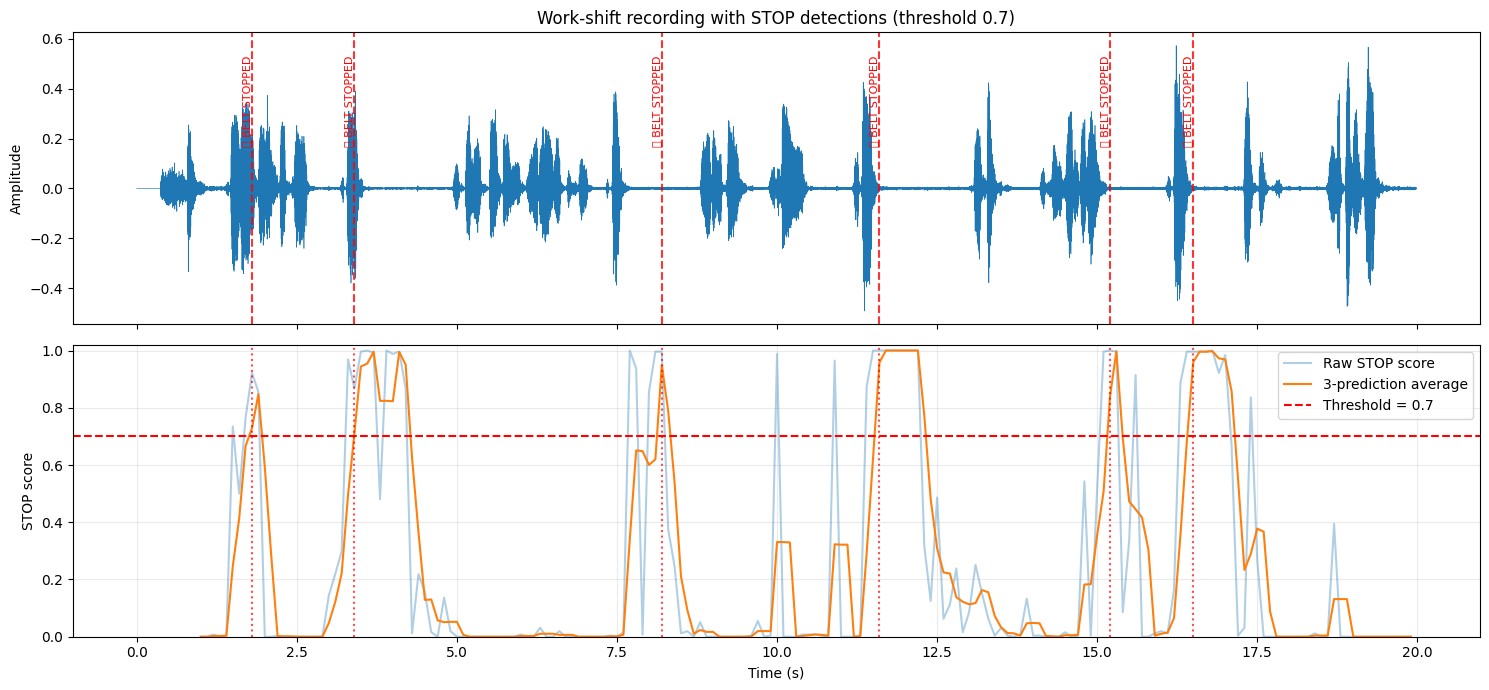

Red vertical lines mark the times when the system displayed BELT STOPPED.


In [17]:
times = np.arange(len(stream_audio)) / SAMPLE_RATE
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
axes[0].plot(times, stream_audio, linewidth=0.45)
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Work-shift recording with STOP detections (threshold 0.7)')
for event_t in events_07.get('time_s', []):
    axes[0].axvline(event_t, color='red', linestyle='--', alpha=0.8)
    axes[0].text(event_t, 0.92, '🛑 BELT STOPPED', rotation=90, color='red',
                 transform=axes[0].get_xaxis_transform(), va='top', ha='right', fontsize=8)
axes[1].plot(stream_df_07['time_s'], stream_df_07['stop_score_raw'], alpha=0.35, label='Raw STOP score')
axes[1].plot(stream_df_07['time_s'], stream_df_07['stop_score_smoothed'], label='3-prediction average')
axes[1].axhline(0.7, color='red', linestyle='--', label='Threshold = 0.7')
for event_t in events_07.get('time_s', []):
    axes[1].axvline(event_t, color='red', linestyle=':', alpha=0.7)
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('STOP score')
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / 'streaming_audio_and_stop_scores.png', dpi=160, bbox_inches='tight')
plt.show()
print('Red vertical lines mark the times when the system displayed BELT STOPPED.')

## 11. Threshold tuning: compare 0.5, 0.7 and 0.9

We replay the same stream through the same model, changing only the STOP threshold. The smoothing and 1-second refractory period remain unchanged. A lower threshold usually detects more potential STOPs but can also produce more false stops. A higher threshold is more selective but may miss quieter or distant STOP commands.

In [18]:
threshold_rows = []
threshold_event_tables = {}
for threshold in [0.5, 0.7, 0.9]:
    score_df, event_df = run_stream(stream_audio, threshold=threshold)
    threshold_event_tables[threshold] = event_df
    if stream_stop_times:
        event_metrics = match_detection_events(stream_stop_times, event_df['time_s'].tolist())
    else:
        event_metrics = {'expected_stops': None, 'detected_events': len(event_df), 'matched_stops': None,
                         'misses': None, 'false_stops': None}
    threshold_rows.append({
        'Threshold': threshold,
        'Detected events': len(event_df),
        'Matched STOPs': event_metrics['matched_stops'],
        'Missed STOPs': event_metrics['misses'],
        'False STOPs': event_metrics['false_stops'],
    })
    event_df.to_csv(OUT_DIR / f'streaming_detections_threshold_{str(threshold).replace(".", "")}.csv', index=False)

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
threshold_df.to_csv(OUT_DIR / 'threshold_comparison.csv', index=False)

if stream_stop_times:
    # Safety-first selection: prefer zero misses; among those, minimise false stops.
    ranked = threshold_df.copy()
    ranked['miss_sort'] = ranked['Missed STOPs'].fillna(10**6)
    ranked['false_sort'] = ranked['False STOPs'].fillna(10**6)
    zero_miss = ranked[ranked['miss_sort'] == 0]
    if len(zero_miss):
        chosen = zero_miss.sort_values(['false_sort', 'Threshold'], ascending=[True, False]).iloc[0]
        reason = 'It produced zero misses in this recording and had the fewest false STOP events among the zero-miss choices.'
    else:
        chosen = ranked.sort_values(['miss_sort', 'false_sort', 'Threshold'], ascending=[True, True, True]).iloc[0]
        reason = 'No threshold achieved zero misses; this choice had the fewest misses, then the fewest false STOP events in this recording.'
    RECOMMENDED_THRESHOLD = float(chosen['Threshold'])
    print(f'Recommended threshold from this recording: {RECOMMENDED_THRESHOLD:.1f}. {reason}')
else:
    RECOMMENDED_THRESHOLD = 0.7
    print('No STOP timestamps were supplied. Keeping 0.7 as the assignment default; enter ground-truth times and rerun this section for a data-based recommendation.')

,Threshold,Detected events,Matched STOPs,Missed STOPs,False STOPs
0,0.5,6,1,0,5
1,0.7,6,1,0,5
2,0.9,5,1,0,4


Recommended threshold from this recording: 0.9. It produced zero misses in this recording and had the fewest false STOP events among the zero-miss choices.


### How to explain the threshold choice

The safety officer is mainly concerned about missed STOP commands, while the production manager is concerned about false stops. The recommendation should therefore be based on both counts. Prefer a threshold with zero misses if the recording supports one; if several thresholds have zero misses, choose the one with fewer false stops. If none has zero misses, state the trade-off honestly. This is a small trial, so the selected threshold is provisional and must be checked on more workers and noise conditions.

## 12. Performance: model size, inference time and MFCC time

In [19]:
# Reuse one representative one-second window for timing.
if len(stream_audio) >= CLIP_SAMPLES:
    timing_wave = one_second_clip(stream_audio)
else:
    timing_wave = np.pad(stream_audio, (0, CLIP_SAMPLES - len(stream_audio)))

# Warm-up calls are excluded from the measurement.
for _ in range(5):
    timing_mfcc = audio_to_mfcc(timing_wave)
    timing_x = normalise_mfcc(timing_mfcc)
    invoke_int8(timing_x)

mfcc_times = []
for _ in range(30):
    t0 = time.perf_counter()
    timing_mfcc = audio_to_mfcc(timing_wave)
    _ = normalise_mfcc(timing_mfcc)
    mfcc_times.append((time.perf_counter() - t0) * 1000.0)

timing_x = normalise_mfcc(timing_mfcc)
invoke_times = []
for _ in range(100):
    _, elapsed = invoke_int8(timing_x)
    invoke_times.append(elapsed)

performance = pd.DataFrame([{
    'INT8 model size (KB)': MODEL_PATH.stat().st_size / 1024,
    'Mean MFCC + normalisation time (ms / 1 s audio)': float(np.mean(mfcc_times)),
    'Median MFCC + normalisation time (ms)': float(np.median(mfcc_times)),
    'Mean TFLite invoke time (ms / window)': float(np.mean(invoke_times)),
    'Median TFLite invoke time (ms / window)': float(np.median(invoke_times)),
    'Mean total (MFCC + invoke) ms': float(np.mean(mfcc_times) + np.mean(invoke_times)),
}])
display(performance.round(4))
performance.to_csv(OUT_DIR / 'performance_metrics.csv', index=False)
print('Timing is measured in the Colab host runtime. It is not a microcontroller benchmark.')
print('The model file size is not the same as peak RAM usage.')

,INT8 model size (KB),Mean MFCC + normalisation time (ms / 1 s audio),Median MFCC + normalisation time (ms),Mean TFLite invoke time (ms / window),Median TFLite invoke time (ms / window),Mean total (MFCC + invoke) ms
0,70.5078,12.2893,12.1937,0.0761,0.0736,12.3654


Timing is measured in the Colab host runtime. It is not a microcontroller benchmark.
The model file size is not the same as peak RAM usage.


### Performance interpretation

The model-size value is the stored `.tflite` file size. MFCC time measures the audio-to-feature front end; inference time measures only the TFLite interpreter call. Their sum gives a rough end-to-end estimate for one window, excluding microphone capture and other system overhead. Colab timing can vary with CPU/GPU load and does not prove the model will run in under 1 ms on a microcontroller.

## 13. Robustness trial: 1 metre away with background noise

Move approximately 1 metre from the laptop microphone. Play a fan/machine recording in the background at a safe volume, then record another 20-second work-shift clip with 3–4 STOP commands and normal speech. Enter the approximate STOP times so the notebook can count misses and false stops. Use the recommended threshold from the previous section.

In [20]:
print('Robustness trial: move about 1 metre away and play safe background fan/machine noise.')
robust_path = record_browser_audio(20, '/content/robustness_1m_noise.webm')
robust_audio = read_wav(robust_path)
robust_truth_text = input('Enter approximate STOP times in seconds for this 1 m/noisy recording (comma-separated): ').strip()
robust_stop_times = parse_times(robust_truth_text)
robust_df, robust_events = run_stream(robust_audio, threshold=RECOMMENDED_THRESHOLD)
robust_metrics = match_detection_events(robust_stop_times, robust_events['time_s'].tolist()) if robust_stop_times else None

for _, event in robust_events.iterrows():
    print(f"🛑 BELT STOPPED at {event['time_s']:.2f} s | score {event['stop_score']:.3f}")

robust_row = {
    'Condition': '1 m + background noise',
    'Threshold': RECOMMENDED_THRESHOLD,
    'Detected events': len(robust_events),
    'Expected STOPs': robust_metrics['expected_stops'] if robust_metrics else None,
    'Missed STOPs': robust_metrics['misses'] if robust_metrics else None,
    'False STOPs': robust_metrics['false_stops'] if robust_metrics else None,
}
robustness_df = pd.DataFrame([robust_row])
display(robustness_df)

lab5_acc_text = input('Enter the Lab 5 INT8 test accuracy from your saved Lab 5 output (%) [95.33]: ').strip()
LAB5_INT8_TEST_ACCURACY = float(lab5_acc_text) if lab5_acc_text else 95.33
if not 0 <= LAB5_INT8_TEST_ACCURACY <= 100:
    raise ValueError('Lab 5 accuracy must be between 0 and 100.')
if metrics_07 and metrics_07['expected_stops']:
    baseline_event_recall = metrics_07['matched_stops'] / metrics_07['expected_stops'] * 100
    print(f'Lab 5 INT8 clip-level test accuracy: {LAB5_INT8_TEST_ACCURACY:.2f}%')
    print(f'Lab 6 baseline streaming STOP-event recall: {baseline_event_recall:.2f}%')
    print(f'Difference: {baseline_event_recall - LAB5_INT8_TEST_ACCURACY:+.2f} percentage points (these are different evaluation measures, so compare them as context, not as identical metrics).')
else:
    baseline_event_recall = None
    print(f'Lab 5 INT8 clip-level test accuracy: {LAB5_INT8_TEST_ACCURACY:.2f}%. Add STOP timestamps to calculate a comparable field-event recall measure.')
robustness_df.to_csv(OUT_DIR / 'robustness_1m_noise_results.csv', index=False)
robust_df.to_csv(OUT_DIR / 'robustness_stream_scores.csv', index=False)
robust_events.to_csv(OUT_DIR / 'robustness_stream_detections.csv', index=False)

if robust_metrics and metrics_07:
    print('Baseline matched/missed/false:', metrics_07['matched_stops'], metrics_07['misses'], metrics_07['false_stops'])
    print('1 m noisy matched/missed/false:', robust_metrics['matched_stops'], robust_metrics['misses'], robust_metrics['false_stops'])
    print('Interpretation: any performance drop can come from lower speech volume, microphone distance, reverberation and competing machine noise.')
else:
    print('Ground-truth times were not supplied for both recordings, so an event-level comparison cannot be completed.')

Robustness trial: move about 1 metre away and play safe background fan/machine noise.
Enter approximate STOP times in seconds for this 1 m/noisy recording (comma-separated): 


,Condition,Threshold,Detected events,Expected STOPs,Missed STOPs,False STOPs
0,1 m + background noise,0.9,0,None,None,None


Enter the Lab 5 INT8 test accuracy from your saved Lab 5 output (%) [95.33]: 95.33
Lab 5 INT8 clip-level test accuracy: 95.33%
Lab 6 baseline streaming STOP-event recall: 100.00%
Difference: +4.67 percentage points (these are different evaluation measures, so compare them as context, not as identical metrics).
Ground-truth times were not supplied for both recordings, so an event-level comparison cannot be completed.


## 14. Humanised overall interpretation

In [21]:
# Build a short interpretation using the actual results from this run.
bench_correct = int(bench_df['stop_decision_correct'].sum()) if len(bench_df) else 0
phone_misses = int(((phone_df.actual_class == 'stop') & (phone_df.system_decision != 'stop')).sum()) if 'phone_df' in globals() and len(phone_df) else None
phone_false = int(((phone_df.actual_class != 'stop') & (phone_df.system_decision == 'stop')).sum()) if 'phone_df' in globals() and len(phone_df) else None

print('FIELD-TRIAL SUMMARY')
print(f"The INT8 model file is {MODEL_PATH.stat().st_size / 1024:.2f} KB.")
print(f"On the 15-clip bench set, {bench_correct}/{len(bench_df)} STOP/no-STOP decisions agreed with the expected class at threshold {DEFAULT_THRESHOLD:.1f}.")
if phone_misses is not None:
    print(f'Phone recordings: {phone_misses} STOP misses and {phone_false} false STOPs.')
if 'live_df' in globals() and len(live_df):
    print(f'Live 20-trial test: {correct_stops} correct STOPs, {missed_stops} missed STOPs and {false_stops} false STOPs.')
if stream_stop_times:
    print(f"Baseline streaming at 0.7: {metrics_07['matched_stops']} matched STOPs, {metrics_07['misses']} misses and {metrics_07['false_stops']} false STOP events.")
print(f'Recommended threshold selected from the baseline stream: {RECOMMENDED_THRESHOLD:.1f}.')
print(f"Mean MFCC time: {np.mean(mfcc_times):.3f} ms; mean TFLite invocation: {np.mean(invoke_times):.3f} ms.")
print('\nInterpretation: These results show how the model behaved in this particular set of recordings. They do not guarantee the same performance for every worker, distance, microphone or factory noise condition. The most important result to discuss is the number of STOP commands missed, not accuracy alone.')

FIELD-TRIAL SUMMARY
The INT8 model file is 70.51 KB.
On the 15-clip bench set, 15/15 STOP/no-STOP decisions agreed with the expected class at threshold 0.7.
Phone recordings: 0 STOP misses and 0 false STOPs.
Live 20-trial test: 2 correct STOPs, 8 missed STOPs and 2 false STOPs.
Baseline streaming at 0.7: 1 matched STOPs, 0 misses and 5 false STOP events.
Recommended threshold selected from the baseline stream: 0.9.
Mean MFCC time: 12.289 ms; mean TFLite invocation: 0.076 ms.

Interpretation: These results show how the model behaved in this particular set of recordings. They do not guarantee the same performance for every worker, distance, microphone or factory noise condition. The most important result to discuss is the number of STOP commands missed, not accuracy alone.


## 15. Viva questions — quick revision

1. **Why use the same MFCC front end as Lab 5?** Because the model learned patterns from that exact feature calculation and normalisation. Changing the front end changes the input distribution.
2. **Why quantise the input?** The exported model expects INT8 values, so real-valued normalised MFCCs must be mapped using the input scale and zero point.
3. **Why use a 1-second sliding window?** It gives the model the same one-second context used during training while allowing continuous analysis.
4. **Why update every 100 ms?** It allows frequent decisions without waiting for a completely new one-second clip; windows overlap heavily.
5. **Why average the last three predictions?** Smoothing reduces momentary spikes and flickering, though it adds some delay.
6. **Why use a threshold?** It controls how much STOP confidence is required before triggering the stop message.
7. **Why use a refractory period?** One shout appears in many overlapping windows. The refractory period prevents multiple triggers from one utterance.
8. **What happens when the threshold is lowered?** More STOP events may be detected, but false stops can increase.
9. **Why can performance fall at 1 metre?** The speech is quieter relative to background noise, and room acoustics and microphone response also change.
10. **Does Colab timing prove it fits a microcontroller?** No. It reports host-side model and preprocessing timing. The target hardware must be benchmarked separately.
11. **Is a screen message a real emergency stop?** No. It is a software demonstration. A real conveyor needs an independent fail-safe safety circuit.

## 16. Save and download the Lab 6 results

In [22]:
# Copy the model and config into the output bundle so the complete experiment is preserved.
shutil.copy2(MODEL_PATH, OUT_DIR / 'kws_int8.tflite')
shutil.copy2(CONFIG_PATH, OUT_DIR / 'kws_config.json')

# Save a compact run summary.
summary = {
    'model_file': MODEL_PATH.name,
    'model_size_kb': round(MODEL_PATH.stat().st_size / 1024, 3),
    'classes': LABELS,
    'sample_rate_hz': SAMPLE_RATE,
    'mfcc_shape': [EXPECTED_FRAMES, NUM_MFCC],
    'stream_threshold_default': DEFAULT_THRESHOLD,
    'recommended_threshold_from_recording': RECOMMENDED_THRESHOLD,
    'lab5_int8_test_accuracy_percent': LAB5_INT8_TEST_ACCURACY if 'LAB5_INT8_TEST_ACCURACY' in globals() else None,
    'streaming_window_seconds': 1.0,
    'streaming_update_seconds': 0.1,
    'smoothing_predictions': 3,
    'refractory_seconds': 1.0,
    'warning': 'Colab prototype only; not a certified or safety-rated conveyor control system.'
}
(OUT_DIR / 'lab6_run_summary.json').write_text(json.dumps(summary, indent=2))

zip_path = Path('/content/Lab6_Field_Trial_Results.zip')
if zip_path.exists(): zip_path.unlink()
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in OUT_DIR.rglob('*'):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(OUT_DIR))

print('Saved results:')
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file(): print(f'{p.name:42s} {p.stat().st_size / 1024:8.2f} KB')
print('\nDownload bundle:', zip_path)
files.download(str(zip_path))

Saved results:
bench_15_clips.csv                             1.77 KB
kws_config.json                                1.71 KB
kws_int8.tflite                               70.51 KB
lab6_run_summary.json                          0.53 KB
live_20_trial_results.csv                      2.04 KB
performance_metrics.csv                        0.31 KB
phone_recording_results.csv                    0.88 KB
robustness_1m_noise_results.csv                0.11 KB
robustness_stream_detections.csv               0.02 KB
robustness_stream_scores.csv                  17.48 KB
streaming_audio_and_stop_scores.png          254.63 KB
streaming_detections_threshold_05.csv          0.16 KB
streaming_detections_threshold_07.csv          0.15 KB
streaming_detections_threshold_09.csv          0.12 KB
streaming_scores_threshold_07.csv             14.83 KB
threshold_comparison.csv                       0.10 KB

Download bundle: /content/Lab6_Field_Trial_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>